# Department for Transport: Town Centres

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df= pd.read_excel("dft_LSOA_towncentres.xlsx", sheet_name='2019')
print("Dataset shape:", df.shape)
df.head()

Dataset shape: (32844, 41)


,LSOA_code,Region,LA_Code,LA_Name,Town_pop,TownPTt,TownPT15n,TownPT30n,TownPT45n,TownPT60n,...,TownCar60pct,TownWalkt,TownWalk15n,TownWalk30n,TownWalk45n,TownWalk60n,TownWalk15pct,TownWalk30pct,TownWalk45pct,TownWalk60pct
0,E01000001,London,E09000001,City of London,863.214592,22.077283,0.0,8.126712,10.0,10.0,...,100.0,29.666541,0.0,0.657534,4.000000,8.710046,0.0,65.753424,100.0,100.0
1,E01000002,London,E09000001,City of London,817.885979,21.951554,0.0,8.268675,10.0,10.0,...,100.0,27.496843,0.0,1.000000,3.390361,8.219277,0.0,100.000000,100.0,100.0
2,E01000003,London,E09000001,City of London,805.075699,22.295447,0.0,7.310894,10.0,10.0,...,100.0,26.288544,0.0,1.000000,4.000000,9.669523,0.0,100.000000,100.0,100.0
3,E01000005,London,E09000001,City of London,460.184021,20.167281,0.0,9.158458,10.0,10.0,...,100.0,29.084283,0.0,0.695931,2.569593,9.000000,0.0,43.040686,100.0,100.0
4,E01000006,London,E09000002,Barking and Dagenham,601.834534,9.559374,1.0,9.296501,10.0,10.0,...,100.0,9.559374,1.0,1.000000,3.000000,6.558011,100.0,100.000000,100.0,100.0


# Data Cleaning

In [5]:
#removes all leading and trailing whitespace from the column names
df.columns = df.columns.str.strip()

In [6]:
#check for missing values, duplicate rows/columns, and only display the unique rows
print("Missing values:", df.isnull().sum().sum())
print("Duplicates:", df.duplicated().sum())
print("Unique LSOAs:", df["LSOA_code"].nunique())

Missing values: 0
Duplicates: 0
Unique LSOAs: 32844


No need to remove any rows

# Exploratory Data Analysis

In [ ]:
columns_to_keep = [
    "LSOA_code",
    "Region",
    "LA_Code",
    "LA_Name",
    "Town_pop",

# Mean travel time to nearest town centre
    "TownPTt", #public transport
    "TownCart", #car
    "TownCyct", #Cycling
    "TownWalkt", #Walking

# Percentage able to reach town centre within 30 minutes through Public Transport, Car, Cycling and Walking
    "TownPT30pct",
    "TownCar30pct",
    "TownCyc30pct",
    "TownWalk30pct"
]

town = df[columns_to_keep].copy()

town.head()

,LSOA_code,Region,LA_Code,LA_Name,Town_pop,TownPTt,TownCart,TownCyct,TownWalkt,TownPT30pct,TownCar30pct,TownCyc30pct,TownWalk30pct
0,E01000001,London,E09000001,City of London,863.214592,22.077283,10.513002,14.274875,29.666541,100.0,100.0,100.0,65.753424
1,E01000002,London,E09000001,City of London,817.885979,21.951554,9.849482,13.857530,27.496843,100.0,100.0,100.0,100.000000
2,E01000003,London,E09000001,City of London,805.075699,22.295447,9.562289,13.200025,26.288544,100.0,100.0,100.0,100.000000
3,E01000005,London,E09000001,City of London,460.184021,20.167281,9.631841,14.082398,29.084283,100.0,100.0,100.0,43.040686
4,E01000006,London,E09000002,Barking and Dagenham,601.834534,9.559374,6.963370,7.949779,9.559374,100.0,100.0,100.0,100.000000


We have considered 30minutes because it gives  one consistent and interpretable accessibility threshold across transport modes without carrying the 15, 30, 45 and 60-minute variants into modelling. This prevents unnecessary correlated features.

In [8]:
numeric_cols = [
    "Town_pop",
    "TownPTt",
    "TownCart",
    "TownCyct",
    "TownWalkt",
    "TownPT30pct",
    "TownCar30pct",
    "TownCyc30pct",
    "TownWalk30pct"
]

town[numeric_cols] = town[numeric_cols].apply(pd.to_numeric, errors="coerce")
town[numeric_cols].describe()

,Town_pop,TownPTt,TownCart,TownCyct,TownWalkt,TownPT30pct,TownCar30pct,TownCyc30pct,TownWalk30pct
count,32844.000000,32844.000000,32844.000000,32844.000000,32844.000000,32844.000000,32844.000000,32844.000000,32844.000000
mean,712.006363,20.595381,11.289461,17.390614,36.882434,87.529910,99.585130,89.012760,55.513011
std,142.226618,11.937985,4.204534,10.952378,29.606267,29.014659,5.811588,29.445059,47.104936
min,288.524719,2.492926,5.513736,5.852298,2.492926,0.000000,0.000000,0.000000,0.000000
25%,623.263338,13.763172,8.384023,10.293062,15.732799,100.000000,100.000000,100.000000,0.000000
50%,686.058746,18.323699,10.244726,13.839103,26.741838,100.000000,100.000000,100.000000,81.877281
75%,782.025129,24.321299,13.031071,20.446195,47.802680,100.000000,100.000000,100.000000,100.000000
max,1542.486511,120.000000,120.000000,120.000000,120.000000,100.000000,100.000000,100.000000,100.000000


In [9]:
town.isnull().sum()

LSOA_code        0
Region           0
LA_Code          0
LA_Name          0
Town_pop         0
TownPTt          0
TownCart         0
TownCyct         0
TownWalkt        0
TownPT30pct      0
TownCar30pct     0
TownCyc30pct     0
TownWalk30pct    0
dtype: int64

## Descriptive
### Accessibility to towncentres under each mode

In [ ]:
travel_time_cols= [
    "TownPTt",
    "TownCart",
    "TownCyct",
    "TownWalkt"
]

town[travel_time_cols].describe().round(2)  #to measure the mean, count and standard deviation of each variables in list

,TownPTt,TownCart,TownCyct,TownWalkt
count,32844.00,32844.00,32844.00,32844.00
mean,20.60,11.29,17.39,36.88
std,11.94,4.20,10.95,29.61
min,2.49,5.51,5.85,2.49
25%,13.76,8.38,10.29,15.73
50%,18.32,10.24,13.84,26.74
75%,24.32,13.03,20.45,47.80
max,120.00,120.00,120.00,120.00


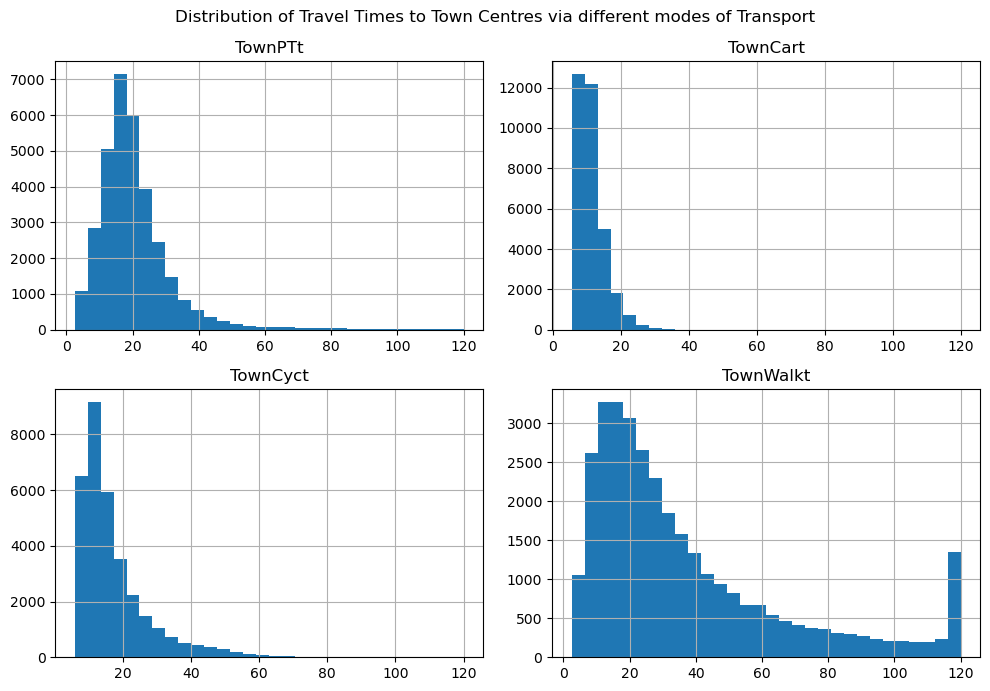

In [13]:
town[travel_time_cols].hist(
    bins=30,
    figsize=(10, 7)
)

plt.suptitle("Distribution of Travel Times to Town Centres via different modes of Transport")
plt.tight_layout()
plt.show()

Car Travel (TownCart): Fastest and most concentrated mode, peaking sharply between 5 and 15 minutes with virtually no journeys exceeding 30 minutes.

Cycling (TownCyct): Highly efficient active mode, peaking around 10 to 15 minutes and dropping off sharply beyond 25 minutes.

Public Transport (TownPTt): Moderately fast, right-skewed distribution peaking around 15 to 20 minutes, with a gradual tail extending up to 50+ minutes.

Walking (TownWalkt): Broadest and slowest mode, peaking between 10 and 20 minutes but exhibiting a wide tail and a spike at 120 minutes (data ceiling), showing that town centres are too far to walk for people in  many regions(LSOAs)

In [15]:
#regional differences.  Note:time measure in minutes
region_summary = (
    town.groupby("Region")[travel_time_cols]
        .mean()
        .round(2)
)

region_summary

,TownPTt,TownCart,TownCyct,TownWalkt
Region,,,,
East,23.69,12.46,20.43,45.36
East Midlands,23.06,12.45,20.53,46.61
London,14.25,9.15,10.95,18.00
North East,21.41,11.85,19.83,41.49
North West,18.93,10.61,15.64,31.69
South East,21.02,11.43,17.67,38.31
South West,23.03,11.96,19.69,43.33
West Midlands,21.00,11.22,17.06,36.14
Yorkshire and The Humber,22.75,12.01,19.61,43.87


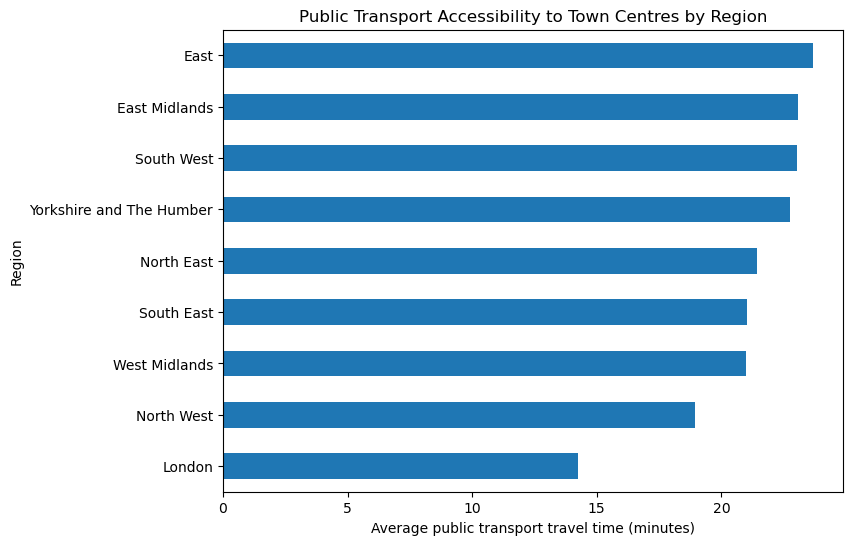

In [16]:
region_summary["TownPTt"].sort_values().plot(
    kind="barh",
    figsize=(8, 6)
)

plt.xlabel("Average public transport travel time (minutes)")
plt.ylabel("Region")
plt.title("Public Transport Accessibility to Town Centres by Region")
plt.show()

London has the shortest average public transport travel time to town centers (~14.2 minutes), driven by high urban density and comprehensive transit connections.
The East region records the highest average travel time (~23.6 minutes), closely followed by the East Midlands and South West (~23 minutes).
Compared to hospital access, town center travel times show a smaller gap across English regions-ranging from ~14 to ~24 minutes indicating a more decentralized distribution of local commercial centers.

### Accessibility to towncentres within 30 minutes

In [17]:
access_30_cols = [
    "TownPT30pct",
    "TownCar30pct",
    "TownCyc30pct",
    "TownWalk30pct"
]

town[access_30_cols].describe().round(2)

,TownPT30pct,TownCar30pct,TownCyc30pct,TownWalk30pct
count,32844.00,32844.00,32844.00,32844.00
mean,87.53,99.59,89.01,55.51
std,29.01,5.81,29.45,47.10
min,0.00,0.00,0.00,0.00
25%,100.00,100.00,100.00,0.00
50%,100.00,100.00,100.00,81.88
75%,100.00,100.00,100.00,100.00
max,100.00,100.00,100.00,100.00


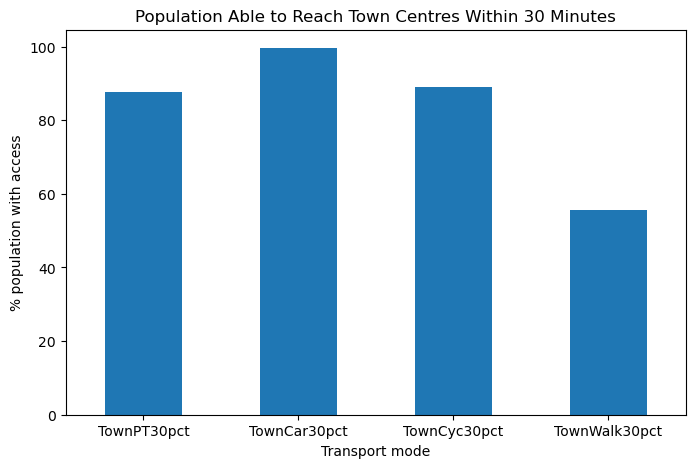

In [18]:
town[access_30_cols].mean().plot(
    kind="bar",
    figsize=(8, 5)
)

plt.ylabel("% population with access")
plt.xlabel("Transport mode")
plt.title("Population Able to Reach Town Centres Within 30 Minutes")
plt.xticks(rotation=0)
plt.show()

Universal Car Access: 100% of the population can reach a town centre within 30 minutes by car, while public transport and cycling both offer strong accessibility at around 88%-89%. Walking provides the lowest coverage, with only about 55% of the population able to reach a town centre within a 30-minute walk.

#### Correlation

In [22]:
corr_cols = [
    "TownPTt",
    "TownCart",
    "TownCyct",
    "TownWalkt",
    "TownPT30pct",
    "TownCar30pct",
    "TownCyc30pct",
    "TownWalk30pct"
]

corr = town[corr_cols].corr()

print(corr.round(2))

               TownPTt  TownCart  TownCyct  TownWalkt  TownPT30pct  \
TownPTt           1.00      0.82      0.83       0.82        -0.77   
TownCart          0.82      1.00      0.96       0.92        -0.74   
TownCyct          0.83      0.96      1.00       0.96        -0.78   
TownWalkt         0.82      0.92      0.96       1.00        -0.78   
TownPT30pct      -0.77     -0.74     -0.78      -0.78         1.00   
TownCar30pct     -0.27     -0.39     -0.39      -0.20         0.21   
TownCyc30pct     -0.67     -0.76     -0.84      -0.84         0.75   
TownWalk30pct    -0.65     -0.73     -0.71      -0.78         0.50   

               TownCar30pct  TownCyc30pct  TownWalk30pct  
TownPTt               -0.27         -0.67          -0.65  
TownCart              -0.39         -0.76          -0.73  
TownCyct              -0.39         -0.84          -0.71  
TownWalkt             -0.20         -0.84          -0.78  
TownPT30pct            0.21          0.75           0.50  
TownCar30pct   

# Feature Engineering

In [29]:
#Public Transport vs Car acessibility
town["Town_PT_Car_gap"] = (town["TownPTt"] - town["TownCart"])
#Large positive value: public transport users face substantially longer journeys than car users.
#Higher gap: greater potential car dependence / modal accessibility inequality.
town["Town_PT_Car_gap"].describe()

count    32844.000000
mean         9.305921
std          8.820016
min         -5.213727
25%          4.963682
50%          7.802722
75%         11.332288
max        100.663146
Name: Town_PT_Car_gap, dtype: float64

In [31]:
town_features = town[
    [   "LSOA_code", 
        "TownPTt",
        "TownPT30pct",
        "Town_PT_Car_gap",
    ]
].copy()

town_features.head()

,LSOA_code,TownPTt,TownPT30pct,Town_PT_Car_gap
0,E01000001,22.077283,100.0,11.564280
1,E01000002,21.951554,100.0,12.102072
2,E01000003,22.295447,100.0,12.733158
3,E01000005,20.167281,100.0,10.535439
4,E01000006,9.559374,100.0,2.596004


In [32]:
print(town_features.shape)
print(town_features.isnull().sum())
town_features.describe().round(2)

(32844, 4)
LSOA_code          0
TownPTt            0
TownPT30pct        0
Town_PT_Car_gap    0
dtype: int64


,TownPTt,TownPT30pct,Town_PT_Car_gap
count,32844.00,32844.00,32844.00
mean,20.60,87.53,9.31
std,11.94,29.01,8.82
min,2.49,0.00,-5.21
25%,13.76,100.00,4.96
50%,18.32,100.00,7.80
75%,24.32,100.00,11.33
max,120.00,100.00,100.66


The dataset was cleaned and transformed and then the selected features were then saved into a new dataset as shown below

In [33]:
town_features.to_excel(
    "town_centre_features.xlsx",
    index=False
)